In [3]:
from pathlib import Path

import pandas as pd
import geopandas as gpd

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

MOBILE_INTERIM = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "interim"
)

od = pd.read_parquet(
    MOBILE_INTERIM / "sevilla_od_2024-07-15.parquet"
)

zones = gpd.read_file(
    MOBILE_INTERIM / "sevilla_districts_v2.gpkg"
)

print("OD shape:", od.shape)
print("Zones:", len(zones))

print("\nOD columns:")
print(od.columns.tolist())

print("\nZone columns:")
print(zones.columns.tolist())

OD shape: (395076, 19)
Zones: 11

OD columns:
['date', 'hour', 'id_origin', 'id_destination', 'distance', 'activity_origin', 'activity_destination', 'study_possible_origin', 'study_possible_destination', 'residence_province_ine_code', 'residence_province_name', 'income', 'age', 'sex', 'n_trips', 'trips_total_length_km', 'year', 'month', 'day']

Zone columns:
['id', 'name', 'population', 'census_sections', 'census_districts', 'municipalities', 'municipalities_mitma', 'luas_mitma', 'district_ids_in_v1', 'geometry']


In [4]:
od.head()

,date,hour,id_origin,id_destination,distance,activity_origin,activity_destination,study_possible_origin,study_possible_destination,residence_province_ine_code,residence_province_name,income,age,sex,n_trips,trips_total_length_km,year,month,day
0,2024-07-15,20,4109101,14042,>50,infrequent_activity,home,False,False,14,Córdoba,10-15,0-25,male,12.809,1553.645,2024,7,15
1,2024-07-15,12,4109107,14042,>50,infrequent_activity,home,False,False,14,Córdoba,10-15,0-25,male,3.839,437.507,2024,7,15
2,2024-07-15,19,4109108,14042,>50,infrequent_activity,home,False,False,14,Córdoba,10-15,0-25,female,3.619,409.645,2024,7,15
3,2024-07-15,11,4109110,14042,>50,infrequent_activity,home,False,False,14,Córdoba,<10,0-25,male,2.691,332.873,2024,7,15
4,2024-07-15,20,4109101,14042,>50,infrequent_activity,home,False,False,14,Córdoba,<10,25-45,female,2.236,272.796,2024,7,15


In [5]:
sevilla_ids = set(zones["id"].astype(str))

od["id_origin"] = od["id_origin"].astype(str)
od["id_destination"] = od["id_destination"].astype(str)

od["flow_type"] = "external"

od.loc[
    od["id_origin"].isin(sevilla_ids)
    & od["id_destination"].isin(sevilla_ids),
    "flow_type"
] = "intra_sevilla"

od.loc[
    od["id_origin"].isin(sevilla_ids)
    & ~od["id_destination"].isin(sevilla_ids),
    "flow_type"
] = "outbound"

od.loc[
    ~od["id_origin"].isin(sevilla_ids)
    & od["id_destination"].isin(sevilla_ids),
    "flow_type"
] = "inbound"

In [6]:
od.groupby("flow_type")["n_trips"].agg(
    rows="size",
    trips="sum"
)

,rows,trips
flow_type,,
inbound,106544,431472.940
intra_sevilla,183703,1511932.918
outbound,104829,422117.003


In [7]:
hourly = (
    od.groupby(["hour", "flow_type"], as_index=False)
      ["n_trips"]
      .sum()
)

hourly.head()

,hour,flow_type,n_trips
0,0,inbound,6271.224
1,0,intra_sevilla,24975.582
2,0,outbound,5645.433
3,1,inbound,4353.058
4,1,intra_sevilla,21602.114


In [8]:
intra = od[
    od["flow_type"] == "intra_sevilla"
].copy()

In [9]:
intra_od = (
    intra.groupby(
        [
            "date",
            "hour",
            "id_origin",
            "id_destination"
        ],
        as_index=False
    )
    .agg(
        n_trips=("n_trips", "sum"),
        total_length_km=("trips_total_length_km", "sum")
    )
)

print(intra_od.shape)
intra_od.head()

(2901, 6)


,date,hour,id_origin,id_destination,n_trips,total_length_km
0,2024-07-15,0,4109101,4109101,814.978,731.137
1,2024-07-15,0,4109101,4109102,436.133,729.913
2,2024-07-15,0,4109101,4109103,218.750,373.848
3,2024-07-15,0,4109101,4109104,121.501,510.615
4,2024-07-15,0,4109101,4109105,202.641,461.350


In [10]:
origin_hour = (
    intra.groupby(
        [
            "date",
            "hour",
            "id_origin"
        ],
        as_index=False
    )
    .agg(
        trips_originating=("n_trips", "sum"),
        total_length_km=("trips_total_length_km", "sum")
    )
)

In [11]:
destination_hour = (
    intra.groupby(
        [
            "date",
            "hour",
            "id_destination"
        ],
        as_index=False
    )
    .agg(
        trips_arriving=("n_trips", "sum")
    )
)

In [12]:
MOBILE_PROCESSED = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "processed"
)

MOBILE_PROCESSED.mkdir(
    parents=True,
    exist_ok=True
)

intra_od.to_parquet(
    MOBILE_PROCESSED / "sevilla_intra_od_2024-07-15.parquet",
    index=False
)

origin_hour.to_parquet(
    MOBILE_PROCESSED / "sevilla_origin_hour_2024-07-15.parquet",
    index=False
)

destination_hour.to_parquet(
    MOBILE_PROCESSED / "sevilla_destination_hour_2024-07-15.parquet",
    index=False
)

In [13]:
od.groupby("flow_type")["n_trips"].agg(
    rows="size",
    trips="sum"
)

,rows,trips
flow_type,,
inbound,106544,431472.940
intra_sevilla,183703,1511932.918
outbound,104829,422117.003


In [14]:
intra = od[
    od["flow_type"] == "intra_sevilla"
].copy()

intra_od = (
    intra.groupby(
        [
            "date",
            "hour",
            "id_origin",
            "id_destination"
        ],
        as_index=False
    )
    .agg(
        n_trips=("n_trips", "sum"),
        total_length_km=("trips_total_length_km", "sum")
    )
)

print("Aggregated OD rows:", len(intra_od))
print("Total intra-Sevilla trips:", intra_od["n_trips"].sum())

intra_od.head()

Aggregated OD rows: 2901
Total intra-Sevilla trips: 1511932.918


,date,hour,id_origin,id_destination,n_trips,total_length_km
0,2024-07-15,0,4109101,4109101,814.978,731.137
1,2024-07-15,0,4109101,4109102,436.133,729.913
2,2024-07-15,0,4109101,4109103,218.750,373.848
3,2024-07-15,0,4109101,4109104,121.501,510.615
4,2024-07-15,0,4109101,4109105,202.641,461.350


In [15]:
origin_hour = (
    intra.groupby(
        [
            "date",
            "hour",
            "id_origin"
        ],
        as_index=False
    )
    .agg(
        trips=("n_trips", "sum")
    )
)

origin_hour.head()

,date,hour,id_origin,trips
0,2024-07-15,0,4109101,2882.244
1,2024-07-15,0,4109102,2341.183
2,2024-07-15,0,4109103,1784.532
3,2024-07-15,0,4109104,2993.561
4,2024-07-15,0,4109105,2811.224


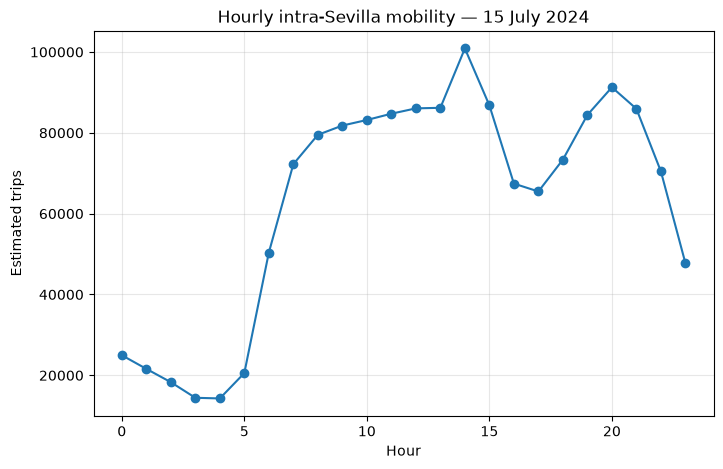

In [17]:
import matplotlib.pyplot as plt

hourly = (
    intra.groupby("hour", as_index=False)
    ["n_trips"]
    .sum()
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    hourly["hour"],
    hourly["n_trips"],
    marker="o"
)

ax.set_xlabel("Hour")
ax.set_ylabel("Estimated trips")
ax.set_title(
    "Hourly intra-Sevilla mobility — 15 July 2024"
)

ax.grid(alpha=0.3)

plt.show()

In [18]:
hourly["share_pct"] = (
    hourly["n_trips"]
    / hourly["n_trips"].sum()
    * 100
)

hourly

,hour,n_trips,share_pct
0,0,24975.582,1.651897
1,1,21602.114,1.428775
2,2,18307.770,1.210885
3,3,14444.541,0.955369
4,4,14280.479,0.944518
5,5,20557.962,1.359714
6,6,50359.336,3.330792
7,7,72243.314,4.778209
8,8,79501.841,5.258292
9,9,81792.863,5.409821


In [19]:
afternoon = hourly[
    hourly["hour"].between(12, 18)
]

afternoon_share = (
    afternoon["n_trips"].sum()
    / hourly["n_trips"].sum()
    * 100
)

print(
    f"Share of intra-Sevilla trips between 12:00 and 18:00: "
    f"{afternoon_share:.1f}%"
)

Share of intra-Sevilla trips between 12:00 and 18:00: 37.4%


In [20]:
def afternoon_share(df):
    hourly = (
        df.groupby("hour", as_index=False)["n_trips"]
          .sum()
    )

    return (
        hourly.loc[
            hourly["hour"].between(12, 18),
            "n_trips"
        ].sum()
        / hourly["n_trips"].sum()
        * 100
    )

In [22]:
daily_afternoon_share = (
    intra.groupby("date")
    .apply(
        afternoon_share,
        include_groups=False
    )
    .reset_index(
        name="afternoon_share_pct"
    )
)

daily_afternoon_share

,date,afternoon_share_pct
0,2024-07-15,37.447841
